# Walsh-PCE paper — final figures, circuits, and LaTeX tables

This notebook is the **single reproducible source for the final manuscript outputs** of `walsh_definitivo`.

Save it as:

`/Users/cesar/Eldorado/walsh_definitivo/analysis/paper_figures_tables.ipynb`

It reads only the final project results and writes:

### Data-driven figures
- `fig_support_scaling` — main text
- `fig_epsilon_window` — main text
- `fig_hardware_shot_sweep` — hardware appendix
- `fig_hardware_graph` — hardware appendix
- `fig_hardware_correlators` — hardware appendix

### Author-drawn circuit figures
- `fig_loader_schematic` — Appendix D
- `fig_single_walsh_factor` — Appendix D

The two circuit figures are drawn directly with **Matplotlib**, not with the Qiskit drawer.

### LaTeX tables
The notebook generates the ten quantitative/specification tables currently used in the manuscript: complete-basis performance, calibrated hyperparameters, support grid, final \(B=1\) random-graph results, Gset specification, Gset results, statevector transfer, hardware validation, hardware resources, and hardware edge list.

All figure filenames are semantic rather than tied to manuscript numbering. Figure numbering is left to LaTeX.


## 1. Setup and final visual style


In [1]:
from pathlib import Path
import os
import json
from decimal import Decimal, ROUND_HALF_UP

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import FancyBboxPatch, Circle, Arc
import networkx as nx
from IPython.display import display


def detect_root():
    candidates = []

    env_root = os.environ.get("WALSH_ROOT")
    if env_root:
        candidates.append(Path(env_root).expanduser())

    cwd = Path.cwd().resolve()
    candidates.extend([
        cwd,
        cwd.parent,
        Path("/Users/cesar/Eldorado/walsh_definitivo"),
    ])

    seen = set()
    for candidate in candidates:
        candidate = candidate.resolve()
        if candidate in seen:
            continue
        seen.add(candidate)
        if (
            (candidate / "results/stage_03/runs.csv").exists()
            and (candidate / "results/stage_04/summary.csv").exists()
            and (candidate / "results/stage_05/summary.csv").exists()
        ):
            return candidate

    raise FileNotFoundError(
        "Could not locate walsh_definitivo. Run this notebook from the repo or analysis/ "
        "directory, or set WALSH_ROOT=/path/to/walsh_definitivo."
    )


ROOT = detect_root()
FIG_DIR = ROOT / "analysis" / "figures"
TAB_DIR = ROOT / "analysis" / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)


# Final manuscript palette: preserved from the legacy notebook, with one warm accent
# reserved for warnings/wrong-sign points.
NAVY = "#12314f"
BLUE = "#1f6091"
TEAL = "#2e94a6"
MINT = "#69c1b0"
PALE = "#bfe3c9"
ORANGE = "#c0703a"
RED = "#b4473d"
LIGHT = "#eef3f6"
DARK = "#1f2933"

CMAP = LinearSegmentedColormap.from_list(
    "walsh_final",
    [NAVY, BLUE, TEAL, MINT, PALE],
)


def paper_style():
    mpl.rcParams.update({
        "font.family": "serif",
        "font.serif": ["STIXGeneral", "DejaVu Serif"],
        "mathtext.fontset": "stix",
        "font.size": 17,
        "axes.titlesize": 19,
        "axes.labelsize": 19,
        "xtick.labelsize": 16,
        "ytick.labelsize": 16,
        "legend.fontsize": 14,
        "axes.edgecolor": "black",
        "axes.linewidth": 1.5,
        "axes.grid": False,
        "xtick.direction": "in",
        "ytick.direction": "in",
        "xtick.top": True,
        "ytick.right": True,
        "xtick.major.size": 8,
        "ytick.major.size": 8,
        "xtick.minor.size": 4,
        "ytick.minor.size": 4,
        "xtick.major.width": 1.3,
        "ytick.major.width": 1.3,
        "xtick.minor.width": 0.9,
        "ytick.minor.width": 0.9,
        "figure.dpi": 120,
        "savefig.dpi": 300,
        "savefig.bbox": "tight",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    })


def size_colors(n, lo=0.05, hi=0.95):
    return [CMAP(t) for t in np.linspace(lo, hi, n)]


def save_figure(fig, stem):
    png = FIG_DIR / f"{stem}.png"
    pdf = FIG_DIR / f"{stem}.pdf"
    fig.savefig(png, dpi=300, bbox_inches="tight")
    fig.savefig(pdf, bbox_inches="tight")
    print("saved:", png)
    print("saved:", pdf)
    return png, pdf


BS = "\\"
ROW = r"\\"


def fmt_half_up(x, digits=3):
    q = Decimal("1").scaleb(-digits)
    return format(
        Decimal(str(float(x))).quantize(q, rounding=ROUND_HALF_UP),
        f".{digits}f",
    )


def tex_sci(x, digits=2):
    if float(x) == 0:
        return "0"
    exp = int(np.floor(np.log10(abs(float(x)))))
    mant = float(x) / (10 ** exp)
    return f"{mant:.{digits}f}{BS}times10^{{{exp}}}"


def write_tex(filename, lines):
    path = TAB_DIR / filename
    text = "\n".join(lines).strip() + "\n"
    path.write_text(text, encoding="utf-8")
    print("saved:", path)
    return path


# Small drawing helpers for the custom circuit figures.
def gate_box(ax, x, y, text, w=0.86, h=0.52, fc="white", ec=DARK, lw=1.5,
             fontsize=15, rounded=True, zorder=5):
    style = "round,pad=0.04,rounding_size=0.06" if rounded else "square,pad=0.02"
    box = FancyBboxPatch(
        (x - w/2, y - h/2), w, h,
        boxstyle=style,
        facecolor=fc, edgecolor=ec, linewidth=lw, zorder=zorder,
    )
    ax.add_patch(box)
    ax.text(x, y, text, ha="center", va="center", fontsize=fontsize, zorder=zorder+1)
    return box


def control_dot(ax, x, y, r=0.065, color=DARK, zorder=7):
    dot = Circle((x, y), r, facecolor=color, edgecolor=color, zorder=zorder)
    ax.add_patch(dot)
    return dot


def target_symbol(ax, x, y, r=0.15, color=DARK, lw=1.5, zorder=7):
    circ = Circle((x, y), r, facecolor="white", edgecolor=color, linewidth=lw, zorder=zorder)
    ax.add_patch(circ)
    ax.plot([x-r*0.7, x+r*0.7], [y, y], color=color, lw=lw, zorder=zorder+1)
    ax.plot([x, x], [y-r*0.7, y+r*0.7], color=color, lw=lw, zorder=zorder+1)
    return circ


def measurement_box(ax, x, y, w=0.76, h=0.54):
    gate_box(ax, x, y, "", w=w, h=h, fc="white")
    arc = Arc((x-0.05, y-0.03), 0.34, 0.28, theta1=20, theta2=160, color=DARK, lw=1.4, zorder=8)
    ax.add_patch(arc)
    ax.plot([x-0.05, x+0.16], [y-0.03, y+0.13], color=DARK, lw=1.4, zorder=8)
    ax.text(x+0.22, y-0.12, "M", fontsize=11, ha="center", va="center", zorder=8)


paper_style()
print("ROOT:", ROOT)
print("FIG_DIR:", FIG_DIR)
print("TAB_DIR:", TAB_DIR)


ROOT: /Users/cesar/Eldorado/walsh_definitivo
FIG_DIR: /Users/cesar/Eldorado/walsh_definitivo/analysis/figures
TAB_DIR: /Users/cesar/Eldorado/walsh_definitivo/analysis/tables


## 2. Final input map


In [2]:
PATHS = {
    "stage02_beta": ROOT / "results/stage_02/selected_beta.csv",
    "stage03_runs": ROOT / "results/stage_03/runs.csv",
    "stage04_runs": ROOT / "results/stage_04/runs.csv",
    "stage04_summary": ROOT / "results/stage_04/summary.csv",
    "support_grid": ROOT / "configs/support_grid.csv",
    "stage05_runs": ROOT / "results/stage_05/runs.csv",
    "stage05_summary": ROOT / "results/stage_05/summary.csv",
    "stage06_epsilon": ROOT / "results/stage_06/01_calibration/epsilon_calibration_all.csv",
    "stage06_statevector": ROOT / "results/stage_06/05_summary/statevector_summary.csv",
    "hw_summary": ROOT / "reference/hardware_n15_final/12_raw_32768_10seeds_20260711_230640/04_summary/raw_32768_10seeds_summary.csv",
    "hw_resources": ROOT / "reference/hardware_n15_final/12_raw_32768_10seeds_20260711_230640/01_estimate/transpiled_resources_selected_seeds.csv",
    "hw_correlators": ROOT / "reference/hardware_n15_final/hw_n15_correlators.csv",
    "hw_edges": ROOT / "reference/hardware_n15_final/hw_n15_edges.csv",
    "hw_problem": ROOT / "reference/hardware_n15_final/hw_n15_problem.json",
    "hw_shot_sweep": ROOT / "reference/hardware_n15_final/hw_shot_sweep.csv",
}

required = [k for k in PATHS if k != "hw_shot_sweep"]
missing = [k for k in required if not PATHS[k].exists()]

for key, path in PATHS.items():
    if path.exists():
        status = "OK"
    elif key == "hw_shot_sweep":
        status = "OPTIONAL COPY NEEDED"
    else:
        status = "MISSING"
    print(f"{key:20s} {status:22s} {path}")

if missing:
    raise FileNotFoundError("Missing required final inputs: " + ", ".join(missing))

for inst in ["G14", "G23", "G60", "G64"]:
    path = ROOT / "data" / "gset" / f"{inst}.txt"
    if not path.exists():
        raise FileNotFoundError(f"Missing Gset input: {path}")

if not PATHS["hw_shot_sweep"].exists():
    print("\nHardware shot-sweep figure will be skipped until this one-time copy is made:")
    print("cp /Users/cesar/Eldorado/vrptw/artigo/analysis/data/hw_shot_sweep.csv \\")
    print("   /Users/cesar/Eldorado/walsh_definitivo/reference/hardware_n15_final/hw_shot_sweep.csv")


stage02_beta         OK                     /Users/cesar/Eldorado/walsh_definitivo/results/stage_02/selected_beta.csv
stage03_runs         OK                     /Users/cesar/Eldorado/walsh_definitivo/results/stage_03/runs.csv
stage04_runs         OK                     /Users/cesar/Eldorado/walsh_definitivo/results/stage_04/runs.csv
stage04_summary      OK                     /Users/cesar/Eldorado/walsh_definitivo/results/stage_04/summary.csv
support_grid         OK                     /Users/cesar/Eldorado/walsh_definitivo/configs/support_grid.csv
stage05_runs         OK                     /Users/cesar/Eldorado/walsh_definitivo/results/stage_05/runs.csv
stage05_summary      OK                     /Users/cesar/Eldorado/walsh_definitivo/results/stage_05/summary.csv
stage06_epsilon      OK                     /Users/cesar/Eldorado/walsh_definitivo/results/stage_06/01_calibration/epsilon_calibration_all.csv
stage06_statevector  OK                     /Users/cesar/Eldorado/walsh_definiti

## 3. Load data and audit the final protocol


In [3]:
stage02_beta = pd.read_csv(PATHS["stage02_beta"])
stage03_runs = pd.read_csv(PATHS["stage03_runs"])
stage04_runs = pd.read_csv(PATHS["stage04_runs"])
stage04_summary = pd.read_csv(PATHS["stage04_summary"])
support_grid = pd.read_csv(PATHS["support_grid"])
stage05_runs = pd.read_csv(PATHS["stage05_runs"])
stage05_summary = pd.read_csv(PATHS["stage05_summary"])
epsilon_all = pd.read_csv(PATHS["stage06_epsilon"])
statevector = pd.read_csv(PATHS["stage06_statevector"])
hw_summary = pd.read_csv(PATHS["hw_summary"])
hw_resources = pd.read_csv(PATHS["hw_resources"])
hw_correlators = pd.read_csv(PATHS["hw_correlators"])
hw_edges = pd.read_csv(PATHS["hw_edges"])
hw_problem = json.loads(PATHS["hw_problem"].read_text())

# Stage 03: held-out complete-basis evaluation
assert len(stage03_runs) == 14_000
assert set(stage03_runs.groupby("n")["graph_id"].nunique()) == {200}
assert set(stage03_runs.groupby("n")["init_seed"].nunique()) == {10}
assert set(stage03_runs["epochs"]) == {500}
assert np.allclose(stage03_runs["lr"], 1e-3)

# Stage 04: support sweep
assert len(stage04_runs) == 43_000
assert int(stage04_summary["zero_cuts"].sum()) == 0
assert set(stage04_runs.groupby(["n", "B"])["init_seed"].nunique()) == {5}

sat = support_grid.loc[support_grid.groupby("n")["B"].idxmax()]
assert np.all(sat["active_size"].to_numpy() == sat["full_size"].to_numpy())

# Stage 05: final B=1 Gset benchmark
assert len(stage05_runs) == 40
assert set(stage05_summary["instance"]) == {"G14", "G23", "G60", "G64"}
assert set(stage05_summary["B"]) == {1}
assert set(stage05_runs.groupby("instance")["init_seed"].nunique()) == {10}

# Stage 06: strict statevector transfer
assert len(statevector) == 4
assert set(statevector["instance"]) == {"G14", "G23", "G60", "G64"}
assert np.allclose(statevector["er"], 0.02)
assert np.allclose(statevector["raw_cut_difference_stage5"], 0)
assert np.allclose(statevector["local_cut_difference_stage5"], 0)
assert np.allclose(statevector["correlator_sign_agreement"], 1)

# Final hardware capsule
assert int(hw_summary.iloc[0]["requested_shots"]) == 32768
assert int(hw_summary.iloc[0]["n_seeds"]) == 10
assert len(hw_correlators) == 150
assert int(hw_problem["n_vertices"]) == 15
assert int(hw_problem["n_edges"]) == 30
assert float(hw_problem["optimum_cut"]) == 24.0
assert int(hw_problem["q_data"]) == 6
assert int(hw_problem["q_total"]) == 7

print("All final-protocol checks passed.")


All final-protocol checks passed.


## 4. Table 1 — complete-basis performance on held-out random graphs


In [4]:
rows = []
for (n, q, k), g in stage03_runs.groupby(["n", "q", "k"], sort=True):
    best_per_graph = g.groupby("graph_id")["AR"].max()
    rows.append({
        "m": int(n),
        "q": int(q),
        "k": int(k),
        "mean": g["AR"].mean(),
        "std": g["AR"].std(ddof=1),
        "p5": g["AR"].quantile(0.05),
        "best10": best_per_graph.mean(),
        "frac98": (g["AR"] >= 0.98).mean(),
    })

full_tbl = pd.DataFrame(rows)
display(full_tbl)

body = []
for _, r in full_tbl.iterrows():
    body.append(
        f"{int(r['m']):,} & {int(r['q'])} & {int(r['k'])} & "
        f"${r['mean']:.4f} {BS}pm {r['std']:.4f}$ & "
        f"${r['p5']:.4f}$ & ${r['best10']:.4f}$ & ${fmt_half_up(r['frac98'], 3)}$ {ROW}"
    )

lines = [
    r"\begin{table}[!h]",
    r"\centering",
    r"\caption{Performance of the complete Walsh basis on the held-out random-graph evaluation set. The reported standard deviation is pooled over graph instances and coefficient initializations.}",
    r"\label{tab:full_basis_performance}",
    r"\begin{tabular}{rrrcccc}",
    r"\toprule",
    r"$m$ & $q$ & $k$ & $\overline{\mathrm{AR}}\pm\sigma$ & $p_5$ & \emph{best-of-10} & $\mathrm{AR}\geq0.98$ \\",
    r"\midrule",
    *body,
    r"\bottomrule",
    r"\end{tabular}",
    r"\end{table}",
]
write_tex("tab_full_basis_performance.tex", lines)


,m,q,k,mean,std,p5,best10,frac98
0,100,9,4,0.976247,0.013487,0.951531,0.992278,0.4190
1,200,10,5,0.975866,0.009923,0.958329,0.989178,0.3635
2,400,11,5,0.976516,0.007152,0.964874,0.986702,0.3180
3,500,12,6,0.975221,0.006497,0.964316,0.984344,0.2405
4,800,12,6,0.982621,0.005355,0.973457,0.989987,0.6950
5,2000,14,7,0.979183,0.003304,0.973728,0.984068,0.4030
6,7000,16,8,0.986012,0.006561,0.979339,0.988727,0.8935


saved: /Users/cesar/Eldorado/walsh_definitivo/analysis/tables/tab_full_basis_performance.tex


PosixPath('/Users/cesar/Eldorado/walsh_definitivo/analysis/tables/tab_full_basis_performance.tex')

## 5. Table 2 — calibrated hyperparameters


In [5]:
hp = stage02_beta[["q", "k", "alpha", "beta"]].sort_values(["q", "k"]).copy()
display(hp)

body = [
    f"$({int(r.q)},{int(r.k)})$ & ${r.alpha:g}$ & ${r.beta:.2f}$ {ROW}"
    for _, r in hp.iterrows()
]

lines = [
    r"\begin{table}[!h]",
    r"\centering",
    r"\caption{Hyperparameters selected from the disjoint calibration subset for each random-graph configuration.}",
    r"\label{tab:hyperparameters_random_graphs}",
    r"\begin{tabular}{rrr}",
    r"\toprule",
    r"$(q,k)$ & $\alpha$ & $\beta$ \\",
    r"\midrule",
    *body,
    r"\bottomrule",
    r"\end{tabular}",
    r"\end{table}",
]
write_tex("tab_hyperparameters_random_graphs.tex", lines)


,q,k,alpha,beta
0,9,4,27.0,0.75
1,10,5,22.0,0.75
2,11,5,22.0,0.75
3,12,6,36.0,0.75
4,14,7,42.0,0.50
5,16,8,80.0,0.50


saved: /Users/cesar/Eldorado/walsh_definitivo/analysis/tables/tab_hyperparameters_random_graphs.tex


PosixPath('/Users/cesar/Eldorado/walsh_definitivo/analysis/tables/tab_hyperparameters_random_graphs.tex')

## 6. Main-text figure — support scaling

This is the final Stage 04 experiment: 200 held-out graphs per size, five coefficient initializations, nested paired supports, no zero-cut collapse, and the complete-basis endpoint imported at support saturation.

The plotted statistic is the **mean recovery**, matching the statistic reported in the final \(B=1\) table. The fixed vertical range is retained because the observed final range lies fully inside it and the purpose of the figure is to resolve the small deviations around unity.


saved: /Users/cesar/Eldorado/walsh_definitivo/analysis/figures/fig_support_scaling.png
saved: /Users/cesar/Eldorado/walsh_definitivo/analysis/figures/fig_support_scaling.pdf


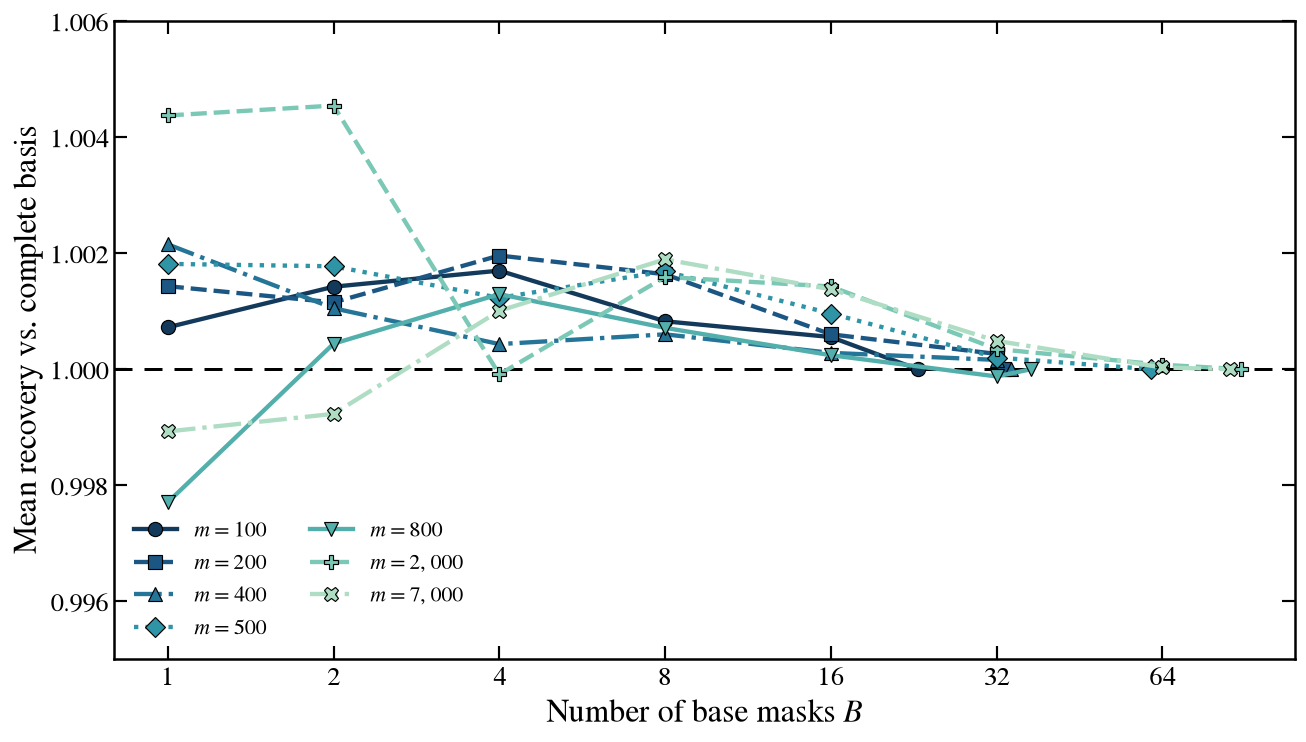

Observed mean-recovery range: 0.9977055120967006 1.0045454127652398


In [6]:
sizes = sorted(stage04_summary["n"].unique())
markers = ["o", "s", "^", "D", "v", "P", "X"]
styles  = ["-", "--", "-.", ":", "-", "--", "-."]
cols = size_colors(len(sizes))

fig, ax = plt.subplots(figsize=(11.2, 6.5))

for m, col, mk, ls in zip(sizes, cols, markers, styles):
    g = stage04_summary.loc[stage04_summary["n"] == m].sort_values("B")
    ax.plot(
        g["B"], g["mean_recovery"],
        ls=ls, marker=mk, color=col,
        lw=2.6, ms=8.5,
        markeredgecolor="black", markeredgewidth=0.7,
        label=fr"$m={m:,}$",
    )

ax.axhline(1.0, ls=(0, (6, 4)), lw=1.8, color="black", zorder=1)
ax.set_xscale("log")
ax.set_xticks([1, 2, 4, 8, 16, 32, 64])
ax.get_xaxis().set_major_formatter(mpl.ticker.ScalarFormatter())
ax.xaxis.set_minor_locator(mpl.ticker.NullLocator())
ax.set_ylim(0.995, 1.006)
ax.set_xlabel(r"Number of base masks $B$")
ax.set_ylabel(r"Mean recovery vs. complete basis")
ax.legend(loc="lower left", frameon=False, ncol=2, fontsize=13)

fig.tight_layout()
save_figure(fig, "fig_support_scaling")
plt.show()

print("Observed mean-recovery range:",
      stage04_summary["mean_recovery"].min(),
      stage04_summary["mean_recovery"].max())


## 7. Table 3 — support grid and realized active-support sizes


In [7]:
body = []
for n, g in support_grid.groupby("n", sort=True):
    g = g.sort_values("B")
    Bs = ",".join(str(int(x)) for x in g["B"])
    As = ",".join(str(int(x)) for x in g["active_size"])
    body.append(f"{int(n):,} & ${Bs}$ & ${As}$ {ROW}")

lines = [
    r"\begin{table}[!h]",
    r"\centering",
    r"\caption{Base-mask values $B$ and resulting active-support sizes $\lvert\mathcal{A}\rvert$ used in the support-scaling experiment. The final entry for each graph size is the first value $B_{\mathrm{sat}}$ for which the paired support reaches the complete Walsh basis.}",
    r"\label{tab:support_grid}",
    r"\setlength{\tabcolsep}{4pt}",
    r"\resizebox{\linewidth}{!}{%",
    r"\begin{tabular}{rll}",
    r"\toprule",
    r"$m$ & $B$ & resulting $\lvert\mathcal{A}\rvert$ \\",
    r"\midrule",
    *body,
    r"\bottomrule",
    r"\end{tabular}%",
    r"}",
    r"\end{table}",
]
write_tex("tab_support_grid.tex", lines)


saved: /Users/cesar/Eldorado/walsh_definitivo/analysis/tables/tab_support_grid.tex


PosixPath('/Users/cesar/Eldorado/walsh_definitivo/analysis/tables/tab_support_grid.tex')

## 8. Table 4 — final single-base model on held-out random graphs


In [8]:
b1 = stage04_summary.loc[stage04_summary["B"] == 1].sort_values("n").copy()

display(
    b1[[
        "n", "active_size", "active_fraction", "mean_AR", "std_AR",
        "mean_recovery", "std_recovery", "p5_recovery"
    ]]
)

body = []
for _, r in b1.iterrows():
    body.append(
        f"{int(r.n):,} & {int(r.active_size):,} & {100*r.active_fraction:.2f}{BS}% & "
        f"${r.mean_AR:.4f} {BS}pm {r.std_AR:.4f}$ & "
        f"${r.mean_recovery:.4f} {BS}pm {r.std_recovery:.4f}$ & "
        f"${r.p5_recovery:.4f}$ {ROW}"
    )

lines = [
    r"\begin{table}[!h]",
    r"\centering",
    r"\caption{Single-base model ($B=1$, $\lvert\mathcal{A}\rvert=m+1$) on the held-out random-graph evaluation set. The retained fraction is measured relative to the complete Walsh basis. Recovery is measured relative to the complete-basis solution.}",
    r"\label{tab:base_mask_b1}",
    r"\begin{tabular}{rrrrcc}",
    r"\toprule",
    r"$m$ & $\lvert\mathcal{A}\rvert$ & retained & $\mathrm{AR}$ & recovery & $p_5$ recovery \\",
    r"\midrule",
    *body,
    r"\bottomrule",
    r"\end{tabular}",
    r"\end{table}",
]
write_tex("tab_base_mask_b1.tex", lines)


,n,active_size,active_fraction,mean_AR,std_AR,mean_recovery,std_recovery,p5_recovery
0,100,101,0.197266,0.976986,0.013556,1.000722,0.013000,0.978894
6,200,201,0.196289,0.976855,0.010021,1.001431,0.010796,0.982637
13,400,401,0.195801,0.978721,0.007084,1.002152,0.008436,0.988984
20,500,501,0.122314,0.977073,0.006554,1.001816,0.007573,0.989244
27,800,801,0.195557,0.980389,0.005339,0.997706,0.006623,0.987605
34,2000,2001,0.122131,0.983477,0.003069,1.004374,0.004238,0.997500
42,7000,7001,0.106827,0.984984,0.006581,0.998926,0.002494,0.994901


saved: /Users/cesar/Eldorado/walsh_definitivo/analysis/tables/tab_base_mask_b1.tex


PosixPath('/Users/cesar/Eldorado/walsh_definitivo/analysis/tables/tab_base_mask_b1.tex')

## 9. Tables 5–6 — Gset specification and final \(B=1\) performance


In [9]:
def gset_weight_label(instance):
    path = ROOT / "data" / "gset" / f"{instance}.txt"
    weights = []
    with path.open() as f:
        next(f)
        for line in f:
            if line.strip():
                weights.append(float(line.split()[2]))
    unique = sorted(set(weights))
    if unique == [1.0]:
        return "+1"
    if unique == [-1.0, 1.0]:
        return f"{BS}pm1"
    return ",".join(f"{x:g}" for x in unique)


gs = stage05_summary.sort_values("instance").copy()
gs["weights"] = [gset_weight_label(x) for x in gs["instance"]]

display(gs[[
    "instance", "n", "edges", "components", "q", "k", "active_size",
    "reference", "weights", "mean_raw_AR", "mean_local_AR"
]])

# Table 5: benchmark specification
body = []
for _, r in gs.iterrows():
    body.append(
        f"{r.instance} & {int(r.n):,} & {int(r.edges):,} & "
        f"${r.weights}$ & {int(r.reference):,} {ROW}"
    )

lines = [
    r"\begin{table}[!h]",
    r"\centering",
    r"\caption{Gset instances used in the final benchmark and the reference value $C_{\mathrm{ref}}$ adopted to normalize solution quality.}",
    r"\label{tab:gset_instances}",
    r"\begin{tabular}{lrrcr}",
    r"\toprule",
    r"Instance & $m$ & $\lvert E\rvert$ & weights & $C_{\mathrm{ref}}$ \\",
    r"\midrule",
    *body,
    r"\bottomrule",
    r"\end{tabular}",
    r"\end{table}",
]
write_tex("tab_gset_instances.tex", lines)

# Table 6: final sparse-model results
body = []
for _, r in gs.iterrows():
    full_size = 2 ** int(r.q)
    reduction = 100 * (1 - r.active_size / full_size)
    best_raw_ar = r.best_raw_cut / r.reference
    best_local_ar = r.best_local_cut / r.reference
    body.append(
        f"{r.instance} & $({int(r.q)},{int(r.k)})$ & "
        f"${int(r.active_size):,}{BS},/{BS},{full_size:,}$ & ${reduction:.1f}{BS}%$ & "
        f"${r.mean_raw_AR:.4f} {BS}pm {r.std_raw_AR:.4f}$ & ${best_raw_ar:.4f}$ & "
        f"${r.mean_local_AR:.4f} {BS}pm {r.std_local_AR:.4f}$ & ${best_local_ar:.4f}$ {ROW}"
    )

lines = [
    r"\begin{table}[!h]",
    r"\centering",
    r"\caption{Single-base $B=1$ model on the Gset instances. The table reports the encoding $(q,k)$, number of active coefficients $\lvert\mathcal{A}\rvert=m+1$ relative to the complete basis $2^q$, parameter reduction, and raw and refined empirical ARs (mean $\pm$ standard deviation and best value over $10$ initializations).}",
    r"\label{tab:gset_ours}",
    r"\setlength{\tabcolsep}{4pt}",
    r"\resizebox{\linewidth}{!}{%",
    r"\begin{tabular}{lccccccc}",
    r"\toprule",
    r"Instance & $(q,k)$ & $\lvert\mathcal{A}\rvert\,/\,2^q$ & reduction & raw AR & best & refined AR & best \\",
    r"\midrule",
    *body,
    r"\bottomrule",
    r"\end{tabular}%",
    r"}",
    r"\end{table}",
]
write_tex("tab_gset_ours.tex", lines)


,instance,n,edges,components,q,k,active_size,reference,weights,mean_raw_AR,mean_local_AR
0,G14,800,4694,1,12,6,801,3064,+1,0.969811,0.982768
1,G23,2000,19990,1,14,7,2001,13344,+1,0.987418,0.992551
2,G60,7000,17148,45,16,8,7001,14188,+1,0.974598,0.978066
3,G64,7000,41459,1,16,8,7001,8751,\pm1,0.919472,0.936921


saved: /Users/cesar/Eldorado/walsh_definitivo/analysis/tables/tab_gset_instances.tex
saved: /Users/cesar/Eldorado/walsh_definitivo/analysis/tables/tab_gset_ours.tex


PosixPath('/Users/cesar/Eldorado/walsh_definitivo/analysis/tables/tab_gset_ours.tex')

## 10. Main-text figure — quantum-transfer \(\epsilon\) window

Uses the final Stage 06 sweep for **G14, G23, G60, and G64**. The dashed vertical line marks the strict validation operating point \(\epsilon=0.02\). No MaxCut quantity is used to select this point.


saved: /Users/cesar/Eldorado/walsh_definitivo/analysis/figures/fig_epsilon_window.png
saved: /Users/cesar/Eldorado/walsh_definitivo/analysis/figures/fig_epsilon_window.pdf


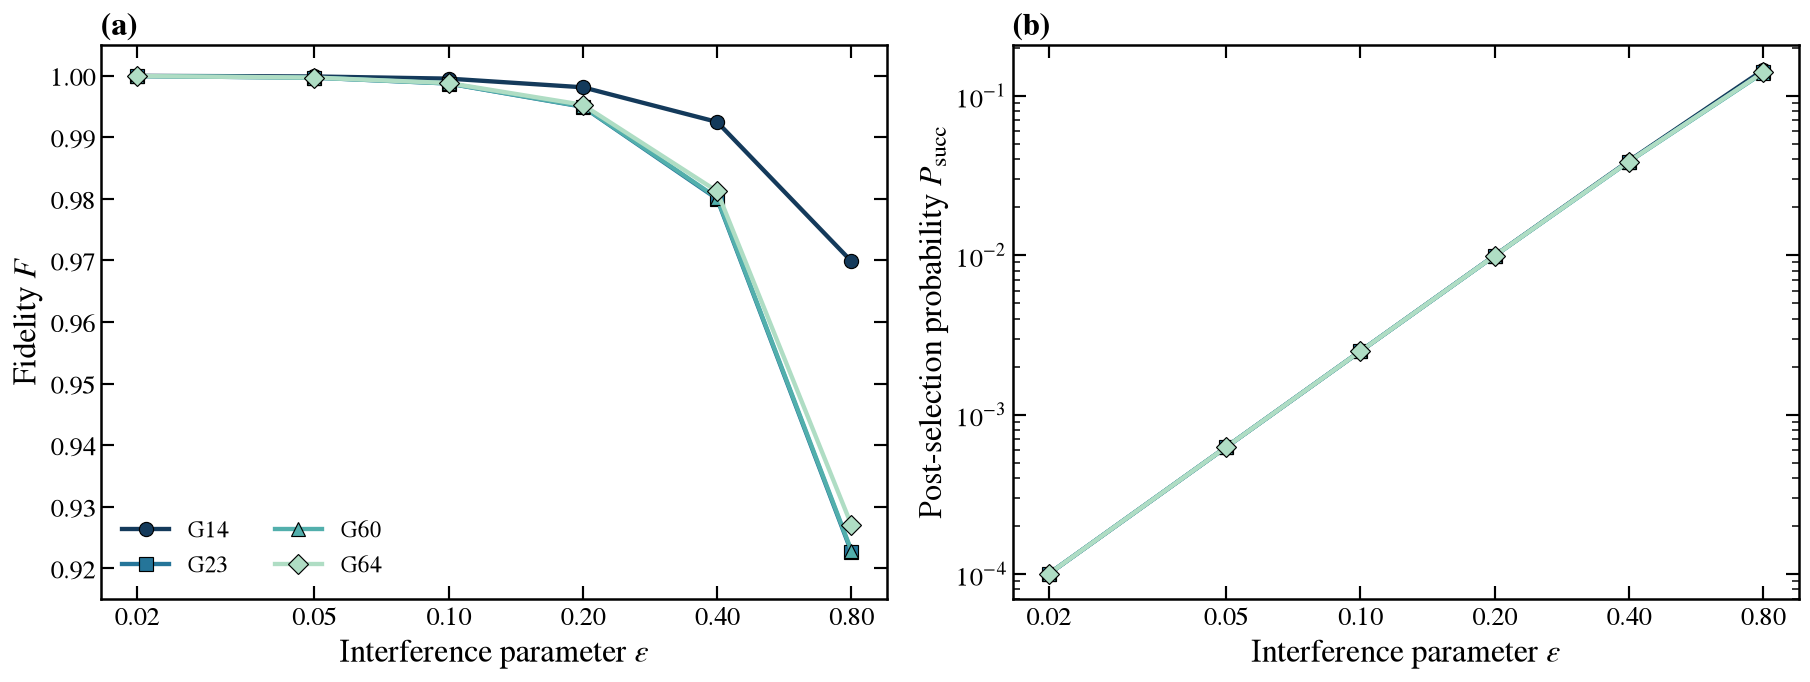

In [21]:
instances = ["G14", "G23", "G60", "G64"]
markers = {"G14": "o", "G23": "s", "G60": "^", "G64": "D"}
cols = dict(zip(instances, size_colors(len(instances))))
eps_values = sorted(epsilon_all["er"].unique())

fig, (axa, axb) = plt.subplots(1, 2, figsize=(15.4, 6.0))

for instance in instances:
    d = epsilon_all.loc[epsilon_all["instance"] == instance].sort_values("er")
    axa.plot(
        d["er"], d["state_fidelity_to_target"],
        marker=markers[instance], color=cols[instance],
        lw=2.6, ms=8.5, markeredgecolor="black", markeredgewidth=0.7,
        label=instance,
    )
    axb.plot(
        d["er"], d["success_probability"],
        marker=markers[instance], color=cols[instance],
        lw=2.6, ms=8.5, markeredgecolor="black", markeredgewidth=0.7,
        label=instance,
    )

for ax in (axa, axb):
    #ax.axvline(0.02, ls=(0, (6, 4)), lw=1.8, color="black")
    ax.set_xscale("log")
    ax.set_xlabel(r"Interference parameter $\epsilon$")
    ax.set_xticks(eps_values)
    ax.get_xaxis().set_major_formatter(mpl.ticker.ScalarFormatter())
    ax.xaxis.set_minor_locator(mpl.ticker.NullLocator())

axa.set_ylabel(r"Fidelity $F$")
axa.set_ylim(0.915, 1.005)
axb.set_yscale("log")
axb.set_ylabel(r"Post-selection probability $P_{\mathrm{succ}}$")
axa.set_title("(a)", loc="left", fontweight="bold")
axb.set_title("(b)", loc="left", fontweight="bold")
axa.legend(loc="lower left", frameon=False, ncol=2)

fig.tight_layout()
save_figure(fig, "fig_epsilon_window")
plt.show()


## 11. Table 7 — strict statevector-transfer validation


In [11]:
sv = statevector.sort_values("instance").copy()
display(sv)

body = []
for _, r in sv.iterrows():
    body.append(
        f"{r.instance} & ${r.success_probability:.1e}$ & "
        f"${r.state_fidelity_target:.6f}$ & ${r.tv_target:.1e}$ & "
        f"${r.correlator_mae:.1e}$ & ${r.correlator_maxae:.1e}$ & "
        f"${r.correlator_sign_agreement:.3f}$ & ${r.raw_AR:.4f}$ & "
        f"${r.local_AR:.4f}$ {ROW}"
    )

lines = [
    r"\begin{table}[H]",
    r"\centering",
    r"\caption{Quantum-transfer validation by statevector simulation at $\epsilon=0.02$ for the training run with the highest raw AR of each instance. We report post-selection success probability, fidelity to the target function state, TV distance, mean and maximum absolute correlator errors relative to the classical calculation, sign agreement, and raw and refined empirical ARs. The cut difference from the classical solution was zero for all instances.}",
    r"\label{tab:transfer_statevector}",
    r"\setlength{\tabcolsep}{3.5pt}",
    r"\resizebox{\linewidth}{!}{%",
    r"\begin{tabular}{lcccccccc}",
    r"\toprule",
    r"Instance & $P_{\rm succ}$ & fidelity & TV & corr. MAE & corr. max AE & sign agreement & raw AR & refined AR \\",
    r"\midrule",
    *body,
    r"\bottomrule",
    r"\end{tabular}%",
    r"}",
    r"\end{table}",
]
write_tex("tab_transfer_statevector.tex", lines)


,instance,seed,er,device,success_probability,state_fidelity_analytic,state_fidelity_target,tv_analytic,tv_target,wall_s,...,raw_spin_agreement,local_spin_agreement,raw_cut,raw_AR,local_cut,local_AR,raw_cut_difference_stage5,local_cut_difference_stage5,flips_forward,flips_backward
0,G14,77,0.02,lightning.qubit,0.0001,1.0,0.999981,1.465585e-15,0.000014,0.230661,...,1.0,1.0,3011.0,0.982702,3027.0,0.987924,0.0,0.0,13,0
1,G23,44,0.02,lightning.qubit,0.0001,1.0,0.999949,2.149759e-15,0.000023,0.505846,...,1.0,1.0,13208.0,0.989808,13287.0,0.995728,0.0,0.0,49,5
2,G60,110,0.02,lightning.qubit,0.0001,1.0,0.999950,4.053946e-15,0.000025,2.692820,...,1.0,1.0,13864.0,0.977164,13915.0,0.980758,0.0,0.0,48,1
3,G64,110,0.02,lightning.qubit,0.0001,1.0,0.999953,4.086482e-15,0.000023,2.773076,...,1.0,1.0,8165.0,0.933036,8306.0,0.949149,0.0,0.0,111,4


saved: /Users/cesar/Eldorado/walsh_definitivo/analysis/tables/tab_transfer_statevector.tex


PosixPath('/Users/cesar/Eldorado/walsh_definitivo/analysis/tables/tab_transfer_statevector.tex')

# Hardware appendix

The hardware experiment remains in the paper as a **validation of transfer and measurability**, not as an optimization advantage claim. The shot sweep is retained only as descriptive evidence; each point uses three coefficient vectors and separate hardware submissions.


## 12. Hardware figure — requested-shot sweep

The final repository archive does not currently contain the consolidated shot-sweep CSV. Copy the already existing aggregate once:

```bash
cp /Users/cesar/Eldorado/vrptw/artigo/analysis/data/hw_shot_sweep.csv \
   /Users/cesar/Eldorado/walsh_definitivo/reference/hardware_n15_final/hw_shot_sweep.csv
```

If it is absent, this cell explicitly skips the figure rather than reconstructing data.


In [12]:
shot_path = PATHS["hw_shot_sweep"]

if not shot_path.exists():
    print("SKIPPED: hw_shot_sweep.csv has not yet been copied into the final project.")
else:
    hw_shots = pd.read_csv(shot_path).sort_values("shot_setting")
    x = hw_shots["shot_setting"]

    fig, ax = plt.subplots(figsize=(9.8, 6.1))

    ax.errorbar(
        x, hw_shots["mean_ar_raw"], yerr=hw_shots["std_ar_raw"],
        fmt="o-", color=BLUE, lw=2.7, ms=9, capsize=5,
        markeredgecolor="black", markeredgewidth=0.7,
        label="AR raw",
    )
    ax.errorbar(
        x, hw_shots["mean_ar_bitflip"], yerr=hw_shots["std_ar_bitflip"],
        fmt="s-", color=ORANGE, lw=2.7, ms=9, capsize=5,
        markeredgecolor="black", markeredgewidth=0.7,
        label="AR refined",
    )
    ax.plot(
        x, hw_shots["mean_sign_agreement_to_exact"],
        "^--", color=TEAL, lw=2.7, ms=9,
        markeredgecolor="black", markeredgewidth=0.7,
        label="sign agreement",
    )

    ax.axhline(1.0, ls=":", lw=1.8, color="black")
    ax.set_xscale("log")
    ax.set_xticks(sorted(hw_shots["shot_setting"].unique()))
    ax.get_xaxis().set_major_formatter(mpl.ticker.ScalarFormatter())
    ax.xaxis.set_minor_locator(mpl.ticker.NullLocator())
    ax.set_xlabel("Requested shots")
    ax.set_ylabel("Quality metric")
    ax.legend(loc="lower right", frameon=False)

    fig.tight_layout()
    save_figure(fig, "fig_hardware_shot_sweep")
    plt.show()


SKIPPED: hw_shot_sweep.csv has not yet been copied into the final project.


## 13. Hardware figure — four-regular \(m=15\) validation graph


saved: /Users/cesar/Eldorado/walsh_definitivo/analysis/figures/fig_hardware_graph.png
saved: /Users/cesar/Eldorado/walsh_definitivo/analysis/figures/fig_hardware_graph.pdf


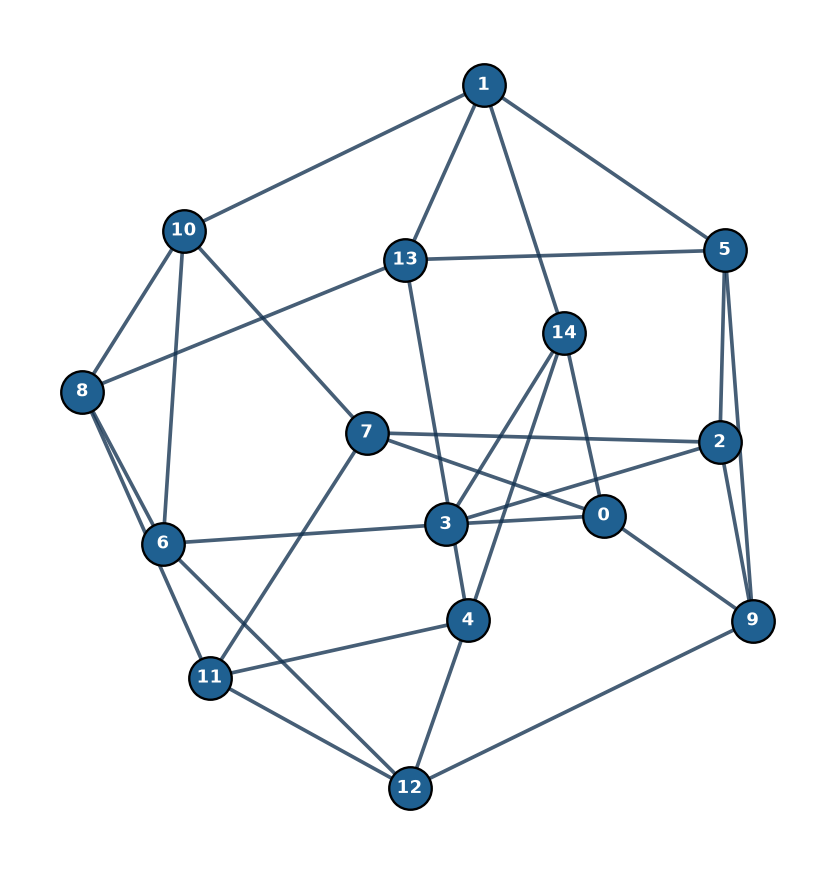

In [13]:
edges = [(int(e["u"]), int(e["v"])) for e in hw_problem["edges"]]
G = nx.Graph()
G.add_nodes_from(range(int(hw_problem["n_vertices"])))
G.add_edges_from(edges)

assert nx.is_connected(G)
assert set(dict(G.degree()).values()) == {4}

pos = nx.spring_layout(G, seed=7, k=0.9)

fig, ax = plt.subplots(figsize=(7.6, 7.6))
nx.draw_networkx_edges(G, pos, ax=ax, edge_color=NAVY, width=2.2, alpha=0.78)
nx.draw_networkx_nodes(
    G, pos, ax=ax,
    node_color=BLUE, node_size=650,
    edgecolors="black", linewidths=1.4,
)
# Small labels are useful in the Appendix because the exact edge list is also given there.
nx.draw_networkx_labels(
    G, pos, ax=ax,
    font_color="white", font_size=11, font_weight="bold",
)

ax.set_axis_off()
ax.set_aspect("equal")
fig.tight_layout()
save_figure(fig, "fig_hardware_graph")
plt.show()


## 14. Hardware figure — measured versus exact finite-\(\epsilon\) correlators

The sign test uses the same convention as the manuscript, \(\operatorname{sgn}(0)=+1\).


saved: /Users/cesar/Eldorado/walsh_definitivo/analysis/figures/fig_hardware_correlators.png
saved: /Users/cesar/Eldorado/walsh_definitivo/analysis/figures/fig_hardware_correlators.pdf


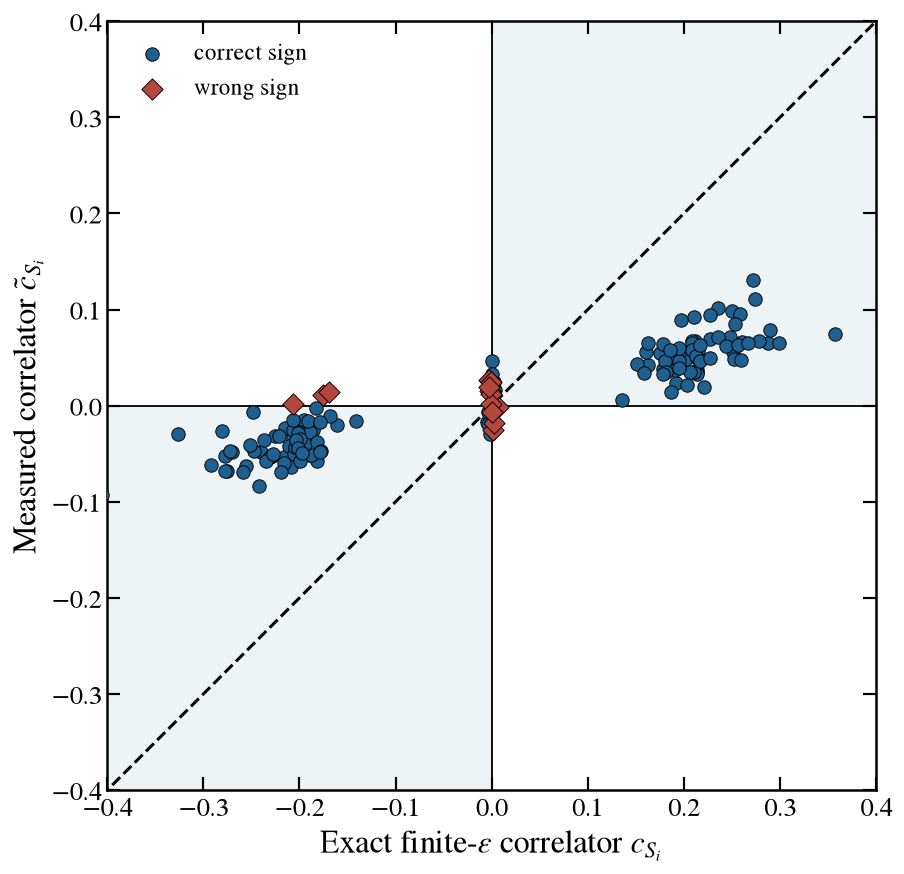

Sign agreement from plotted points: 0.9


In [14]:
cc = hw_correlators.copy()
same = (cc["measured"] >= 0) == (cc["classical"] >= 0)

fig, ax = plt.subplots(figsize=(7.8, 7.6))

# Correct-sign quadrants.
ax.axhspan(-1, 0, xmin=0.0, xmax=0.5, color=LIGHT, zorder=0)
ax.axhspan(0, 1, xmin=0.5, xmax=1.0, color=LIGHT, zorder=0)
ax.axhline(0, color="black", lw=1.1)
ax.axvline(0, color="black", lw=1.1)
ax.plot([-1, 1], [-1, 1], "--", color="black", lw=1.8, zorder=1)

ax.scatter(
    cc.loc[same, "classical"], cc.loc[same, "measured"],
    s=65, color=BLUE, edgecolor="black", linewidth=0.55,
    zorder=3, label="correct sign",
)
ax.scatter(
    cc.loc[~same, "classical"], cc.loc[~same, "measured"],
    s=82, color=RED, edgecolor="black", linewidth=0.55, marker="D",
    zorder=4, label="wrong sign",
)

lim = 0.40
ax.set_xlim(-lim, lim)
ax.set_ylim(-lim, lim)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel(r"Exact finite-$\epsilon$ correlator $c_{S_i}$")
ax.set_ylabel(r"Measured correlator $\tilde c_{S_i}$")
ax.legend(loc="upper left", frameon=False)

fig.tight_layout()
save_figure(fig, "fig_hardware_correlators")
plt.show()

print("Sign agreement from plotted points:", same.mean())


## 15. Table 8 — final real-hardware validation


In [15]:
r = hw_summary.iloc[0]
N = int(r.n_seeds)

raw_match = int(round(r.raw_exact_recovery_rate * N))
refined_match = int(round(r.bitflip_exact_recovery_rate * N))

body = [
    f"Success probability & ${r.mean_observed_success_probability:.3f} {BS}pm {r.std_observed_success_probability:.3f}$ {ROW}",
    f"TV distance to noiseless & ${r.mean_tv_to_exact_circuit:.3f} {BS}pm {r.std_tv_to_exact_circuit:.3f}$ {ROW}",
    f"Correlator MAE to noiseless & ${r.mean_correlator_mae_to_exact:.3f} {BS}pm {r.std_correlator_mae_to_exact:.3f}$ {ROW}",
    f"Sign agreement with noiseless & ${r.mean_sign_agreement_to_exact:.3f} {BS}pm {r.std_sign_agreement_to_exact:.3f}$ {ROW}",
    f"Raw AR & ${r.mean_ar_raw:.3f} {BS}pm {r.std_ar_raw:.3f}$ {ROW}",
    f"Refined AR & ${r.mean_ar_bitflip:.3f} {BS}pm {r.std_ar_bitflip:.3f}$ {ROW}",
    f"Noiseless-cut match (raw) & ${raw_match}/{N}$ {ROW}",
    f"Noiseless-cut match (refined) & ${refined_match}/{N}$ {ROW}",
]

lines = [
    r"\begin{table}[H]",
    r"\centering",
    r"\caption{Hardware validation of the $m=15$ instance on \texttt{ibm\_fez} ($\epsilon=0.6$, $32{,}768$ shots, of which about $5{,}500$ survive post-selection, $10$ initializations). All distribution- and correlator-level errors are evaluated relative to the exact noiseless finite-$\epsilon$ circuit with the same trained coefficients, not to the ideal Walsh target; empirical ARs are reported as mean $\pm$ standard deviation.}",
    r"\label{tab:hardware}",
    r"\begin{tabular}{lc}",
    r"\toprule",
    r"Metric & Value \\",
    r"\midrule",
    *body,
    r"\bottomrule",
    r"\end{tabular}",
    r"\end{table}",
]
write_tex("tab_hardware.tex", lines)


saved: /Users/cesar/Eldorado/walsh_definitivo/analysis/tables/tab_hardware.tex


PosixPath('/Users/cesar/Eldorado/walsh_definitivo/analysis/tables/tab_hardware.tex')

## 16. Table 9 — transpiled hardware resources


In [16]:
hr = hw_resources.copy()

isa_mean = hr["isa_depth"].mean()
isa_min = hr["isa_depth"].min()
isa_max = hr["isa_depth"].max()

size_mean = hr["isa_size"].mean()
size_min = hr["isa_size"].min()
size_max = hr["isa_size"].max()

duration_us = hr["circuit_duration_s"].mean() * 1e6
max_2q = hr["max_two_qubit_error"].max()
max_readout = hr["max_readout_error"].max()

body = [
    f"Active physical qubits & ${int(hr.active_qubit_count.max())}$ {ROW}",
    f"ISA depth & ${isa_mean:.1f}{BS},[{int(isa_min)}{BS}text{{--}}{int(isa_max)}]$ {ROW}",
    f"Two-qubit depth & ${int(hr.isa_two_qubit_depth.max())}$ {ROW}",
    f"Two-qubit gates & ${int(hr.isa_two_qubit_gates.max())}$ {ROW}",
    f"Circuit size & ${size_mean:.1f}{BS},[{int(size_min)}{BS}text{{--}}{int(size_max)}]$ {ROW}",
    f"Circuit duration & ${duration_us:.2f}{BS},{BS}mu{BS}mathrm{{s}}$ {ROW}",
    f"Maximum two-qubit error & ${tex_sci(max_2q, 2)}$ {ROW}",
    f"Maximum readout error & ${tex_sci(max_readout, 2)}$ {ROW}",
]

lines = [
    r"\begin{table}[H]",
    r"\centering",
    r"\caption{Resources of the circuits transpiled for the $m=15$ instance on \texttt{ibm\_fez}, over the $10$ initializations. Quantities that vary across circuits are reported as mean [min--max].}",
    r"\label{tab:hardware_resources}",
    r"\begin{tabular}{lc}",
    r"\toprule",
    r"Resource & Value \\",
    r"\midrule",
    *body,
    r"\bottomrule",
    r"\end{tabular}",
    r"\end{table}",
]
write_tex("tab_hardware_resources.tex", lines)


saved: /Users/cesar/Eldorado/walsh_definitivo/analysis/tables/tab_hardware_resources.tex


PosixPath('/Users/cesar/Eldorado/walsh_definitivo/analysis/tables/tab_hardware_resources.tex')

## 17. Table 10 — hardware-instance edge list


In [17]:
edges = [(int(r.u), int(r.v)) for _, r in hw_edges.iterrows()]
chunks = [edges[i:i+6] for i in range(0, len(edges), 6)]

body = [
    " & ".join(f"$({u},{v})$" for u, v in chunk) + " " + ROW
    for chunk in chunks
]

lines = [
    r"\begin{table}[H]",
    r"\centering",
    r"\caption{Edge list of the four-regular $15$-vertex graph used in the hardware experiment. All edge weights are equal to one.}",
    r"\label{tab:hardware_edge_list}",
    r"\begin{tabular}{cccccc}",
    r"\toprule",
    r"\multicolumn{6}{c}{Edges} \\",
    r"\midrule",
    *body,
    r"\bottomrule",
    r"\end{tabular}",
    r"\end{table}",
]
write_tex("tab_hardware_edge_list.tex", lines)


saved: /Users/cesar/Eldorado/walsh_definitivo/analysis/tables/tab_hardware_edge_list.tex


PosixPath('/Users/cesar/Eldorado/walsh_definitivo/analysis/tables/tab_hardware_edge_list.tex')

# Author-drawn circuit figures

These figures are intentionally **not produced by Qiskit's circuit drawer**. They are manuscript schematics drawn with Matplotlib so that typography, line weights, spacing, and mathematical labels match the rest of the paper.


## 18. Appendix figure — Walsh-loader transfer schematic


## 20. Final output audit


In [20]:
expected_figures = [
    "fig_support_scaling",
    "fig_epsilon_window",
    "fig_hardware_graph",
    "fig_hardware_correlators",
    "fig_loader_schematic",
    "fig_single_walsh_factor",
]
if PATHS["hw_shot_sweep"].exists():
    expected_figures.append("fig_hardware_shot_sweep")

expected_tables = [
    "tab_full_basis_performance.tex",
    "tab_hyperparameters_random_graphs.tex",
    "tab_support_grid.tex",
    "tab_base_mask_b1.tex",
    "tab_gset_instances.tex",
    "tab_gset_ours.tex",
    "tab_transfer_statevector.tex",
    "tab_hardware.tex",
    "tab_hardware_resources.tex",
    "tab_hardware_edge_list.tex",
]

print("Figures")
for stem in expected_figures:
    png = FIG_DIR / f"{stem}.png"
    pdf = FIG_DIR / f"{stem}.pdf"
    print(f"  {stem:34s}", "OK" if png.exists() and pdf.exists() else "MISSING")

if not PATHS["hw_shot_sweep"].exists():
    print("  fig_hardware_shot_sweep            SKIPPED — copy hw_shot_sweep.csv first")

print("\nTables")
for name in expected_tables:
    p = TAB_DIR / name
    print(f"  {name:38s}", "OK" if p.exists() else "MISSING")

print("\nNumerical anchors")
print("  Stage 03 runs:", len(stage03_runs))
print("  Stage 04 zero cuts:", int(stage04_summary.zero_cuts.sum()))
print("  Gset instances:", ", ".join(stage05_summary["instance"]))
print("  Strict-transfer sign agreement:", statevector["correlator_sign_agreement"].tolist())
print("  Hardware sign agreement:", float(hw_summary.iloc[0]["mean_sign_agreement_to_exact"]))

print("\nOutput directories")
print("  figures:", FIG_DIR)
print("  tables :", TAB_DIR)


Figures
  fig_support_scaling                OK
  fig_epsilon_window                 OK
  fig_hardware_graph                 OK
  fig_hardware_correlators           OK
  fig_loader_schematic               OK
  fig_single_walsh_factor            OK
  fig_hardware_shot_sweep            SKIPPED — copy hw_shot_sweep.csv first

Tables
  tab_full_basis_performance.tex         OK
  tab_hyperparameters_random_graphs.tex  OK
  tab_support_grid.tex                   OK
  tab_base_mask_b1.tex                   OK
  tab_gset_instances.tex                 OK
  tab_gset_ours.tex                      OK
  tab_transfer_statevector.tex           OK
  tab_hardware.tex                       OK
  tab_hardware_resources.tex             OK
  tab_hardware_edge_list.tex             OK

Numerical anchors
  Stage 03 runs: 14000
  Stage 04 zero cuts: 0
  Gset instances: G14, G23, G60, G64
  Strict-transfer sign agreement: [1.0, 1.0, 1.0, 1.0]
  Hardware sign agreement: 0.9266666666666664

Output directories
  fi

## 21. LaTeX usage

Use the semantic figure filenames in the manuscript so that moving a figure between the main text and the Appendix does not require renaming the file.

Examples:

```latex
\includegraphics[width=\linewidth]{analysis/figures/fig_support_scaling.pdf}
\includegraphics[width=\linewidth]{analysis/figures/fig_epsilon_window.pdf}
\includegraphics[width=\linewidth]{analysis/figures/fig_hardware_correlators.pdf}
\includegraphics[width=\linewidth]{analysis/figures/fig_loader_schematic.pdf}
\includegraphics[width=\linewidth]{analysis/figures/fig_single_walsh_factor.pdf}
```

For generated tables, either copy the emitted block into the manuscript or use `\input{...}` if the journal build structure permits it.
